# ESPRI 实验 ADC：质子能量重建与同事件对照

**功能**：读取本文件夹 `Ex5sigma.root/tree`，用 `ADC_output/` 的左右臂模型预测顶点质子动能，
保存实验逐事件预测、能量差、能角图、激发能谱和基态/第一激发态局部高斯拟合。
**方法**：直接读取 `naiQPed[4][7]`，按实验 side 和局部棒号取两端扣除 pedestal 后的信号，计算几何平均；
不读取其他 ADC 标量分支，不从能量反算实验 ADC。输入严格为 `[ADC, rdcX[side], rdcY[side], NaIID]`。
NaIID=7*(1−side)+espriNaiBarId+1，Left side=1→1–7，Right side=0→8–14；RDC 坐标不再翻转或平移。
CPU float64、模型保存的归一化和完整模型；不训练。参考 nndl-practice/pytorch/nndl/runner.py 推理模式。
**注意事项**：先运行 EspriADC 保存固定目录模型。原有角度 55–70°、Backtracking Z 5σ、Phi12 门保持。
ADC 输入必须有限且非负、所选棒号有效；两端推导时两端均须为正；逐步报告筛选计数。
模型保存的标定用于检查物理解，不从 naiEnergy 反算实验 ADC；naiEnergy 仅保存作对照。
原 protonEnergy 是传统实验重建结果，不是真值；不得将二者差值解释为网络预测误差。
运动学和缺失质量均调用现有 NuclearMass/TwoBodyKinematics 接口，150 MeV/u；局部 sigma 不是本征分辨率。
输出固定在 `Exp/`，运行覆盖同名产物。运行时生成的 ROOT 辅助宏及中间文件也仅在 Exp 内。
本流程只比较传统重建与 ADC MLP，不加载三输入能量 GPR。所有 Notebook 单元格由用户手动执行。


## 1. 导入与配置
需要 torch、uproot、awkward、numpy、matplotlib；后续物理计算需要本地 ROOT，峰拟合需要 scipy 和 iminuit。


In [1]:
# 功能：加载左右臂 ADC 模型并比较传统实验重建与 ADC MLP 的能量、能角及激发能。
# 方法：选中棒的 pedestal 扣除后 ADC、四输入 CPU float64 推理、相同事件的物理对照。
# 注意事项：只使用固定 ADC_output 模型；输出与 ROOT 中间文件均在 Exp；不训练，传统重建不是真值。
from IPython.display import display, Math
import sys
from time import perf_counter

_startup_time = perf_counter()
print(f"ForADCExperiment started; Python: {sys.executable}", flush=True)
print("Loading awkward / NumPy ...", flush=True)
from pathlib import Path
import hashlib
import json
import shutil
import subprocess
import awkward as ak
import numpy as np
print(f"NumPy ready ({perf_counter() - _startup_time:.1f} s); loading PyTorch ...", flush=True)
import torch
import uproot
print(f"PyTorch / uproot ready ({perf_counter() - _startup_time:.1f} s); loading Matplotlib ...", flush=True)
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
print(f"Dependencies ready ({perf_counter() - _startup_time:.1f} s).", flush=True)

PROJECT_DIR = Path("/Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy")
INPUT_ROOT_DIR = PROJECT_DIR / "InputRootFiles"
WORK_DIR = PROJECT_DIR / "ADCToProtonEnergy"
INPUT_FILE = WORK_DIR / "Ex5sigma.root"
TREE_NAME = "tree"
MODEL_DIR = WORK_DIR / "ADC_output"
OUTPUT_DIR = WORK_DIR / "Exp"
KINEMATICS_MACRO = OUTPUT_DIR / "KinADC.C"
ROOT_EXECUTABLE = shutil.which("root") or "/opt/homebrew/bin/root"

# 每一项同时约定实验 side、模拟 arm 和模型文件，避免把两套编号直接当作相同编号。
ARM_CONFIG = {
    "Left": {"experiment_side": 1, "simulation_arm": 0, "model": MODEL_DIR / "EspriADC_Left.pt"},
    "Right": {"experiment_side": 0, "simulation_arm": 1, "model": MODEL_DIR / "EspriADC_Right.pt"},
}
FEATURE_NAMES = ["ADC", "rdcX", "rdcY", "NaIID"]
FEATURE_UNITS = ["channel", "mm", "mm", "1"]
DTYPE = torch.float64
device = torch.device("cpu")
torch.set_default_dtype(DTYPE)
INVALID_VALUE = -999.0
PREDICT_BATCH_SIZE = 4096

THETA_MIN_DEG, THETA_MAX_DEG = 55.0, 70.0
BACKTRACKING_Z_MEAN_MM = -4.205798
BACKTRACKING_Z_SIGMA_MM = 15.635715
BACKTRACKING_NSIGMA = 5.0
PHI12_CENTER_DEG, PHI12_HALF_WIDTH_DEG = 180.0, 15.0
# 绘图角度范围独立于上方事件筛选范围。
PLOT_THETA_MIN_DEG, PLOT_THETA_MAX_DEG = 50.0, 80.0
THETA_BIN_WIDTH_DEG = 0.1
ENERGY_MIN_MEV, ENERGY_MAX_MEV = 0.0, 180.0
ENERGY_BIN_WIDTH_MEV = 0.1
FRAME_ASPECT_RATIO = 4.0 / 3.0
COLOR_MAP = "rainbow"
plt.rcParams.update({"font.size": 11, "axes.linewidth": 1.0})

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Input:", INPUT_FILE.resolve())
print("Output:", OUTPUT_DIR)
print("Device:", device, "dtype:", DTYPE)
for arm, config in ARM_CONFIG.items():
    print(f"{arm}: exp side={config['experiment_side']} -> sim arm={config['simulation_arm']} -> {config['model'].name}")

# 功能：校验 ADC 模型、预处理及逐棒标定，并提供只读的分批推理。
# 方法：加载可信完整模型，复用训练集 float64 归一化和 checkpoint 内的标定快照。
# 注意事项：只接受本项目四输入/对应臂；不重新训练、不重新拟合归一化。
def load_adc_model(arm):
    path = MODEL_DIR / f"EspriADC_{arm}.pt"
    saved = torch.load(path, map_location="cpu", weights_only=False)
    if (saved["arm"] != arm or list(saved["feature_names"]) != FEATURE_NAMES
            or list(saved["feature_units"]) != FEATURE_UNITS
            or saved["target_name"] != "ETrue" or saved["target_unit"] != "MeV"):
        raise ValueError(f"{arm} 模型臂、特征顺序、单位或目标不匹配。")
    config = saved["configuration"]
    expected_map = {"Left": {"side": 1, "id_min": 1}, "Right": {"side": 0, "id_min": 8}}
    if (config.get("dtype") != "float64" or config.get("arm_calibration_mapping") != expected_map
            or config.get("adc_formula") != "Q=(ENaI-C)/(A-B*(ENaI-C))"
            or config.get("adc_quantized") is not False or config.get("adc_added_noise") is not False):
        raise ValueError("模型的 ADC 定义、精度或编号映射不匹配。")
    raw = config["calibration_text"].encode("utf-8")
    if hashlib.sha256(raw).hexdigest() != config["calibration_sha256"]:
        raise ValueError("模型内标定原文与 SHA256 不一致。")
    table = np.loadtxt(raw.decode("utf-8").splitlines(), ndmin=2, dtype=np.float64)
    if table.shape != (14, 5) or not np.isfinite(table).all() or not np.array_equal(table, np.asarray(config["calibration_table"])):
        raise ValueError("模型内标定表异常。")
    keys = table[:, :2]
    if (set(map(tuple, keys)) != {(s,b) for s in (0,1) for b in range(7)}
            or np.any(table[:, 2] <= 0)):
        raise ValueError("标定键或 A 系数异常。")
    for key, shape in [("x_mean", (4,)), ("x_std", (4,)), ("y_mean", (1,)), ("y_std", (1,)),
                       ("train_feature_min", (4,)), ("train_feature_max", (4,))]:
        value = np.asarray(saved[key], dtype=np.float64)
        if value.shape != shape or not np.isfinite(value).all():
            raise ValueError(f"归一化/范围参数 {key} 异常。")
        saved[key] = value
    if np.any(saved["x_std"] <= 0) or np.any(saved["y_std"] <= 0):
        raise ValueError("模型归一化缩放必须为正。")
    model = saved["model"]
    parameters = list(model.parameters())
    linear = [layer for layer in model.modules() if isinstance(layer, torch.nn.Linear)]
    if (not linear or linear[0].in_features != 4 or linear[-1].out_features != 1
            or any(p.dtype != torch.float64 for p in parameters)):
        raise ValueError("实际网络维度或精度不匹配。")
    saved["model"] = model.to(device=device, dtype=DTYPE).eval()
    saved["checkpoint_path"] = str(path.resolve())
    saved["checkpoint_sha256"] = hashlib.sha256(path.read_bytes()).hexdigest()
    return saved


def predict_saved(saved, X):
    X = np.asarray(X, dtype=np.float64)
    if X.ndim != 2 or X.shape[1] != 4 or not np.isfinite(X).all():
        raise ValueError("推理输入应为有限 N×4 数组。")
    rule = saved["configuration"]["arm_calibration_mapping"][saved["arm"]]
    ids = X[:, 3]
    if (np.any(X[:, 0] < 0) or np.any(ids != np.floor(ids))
            or np.any(ids < rule["id_min"]) or np.any(ids > rule["id_min"] + 6)):
        raise ValueError("ADC 或 NaIID 非物理/臂不匹配。")
    prediction = np.empty(len(X), dtype=np.float64)
    model = saved["model"]
    model.eval()
    for first in range(0, len(X), PREDICT_BATCH_SIZE):
        stop = min(first + PREDICT_BATCH_SIZE, len(X))
        scaled = (X[first:stop] - saved["x_mean"]) / saved["x_std"]
        tensor = torch.from_numpy(np.ascontiguousarray(scaled)).to(device=device, dtype=DTYPE)
        with torch.no_grad():
            values = model(tensor).cpu().numpy()
        if values.shape != (stop-first, 1):
            raise ValueError("模型输出形状不是 (N,1)。")
        prediction[first:stop] = (values * saved["y_std"] + saved["y_mean"]).reshape(-1)
    if not np.isfinite(prediction).all():
        raise ValueError("预测出现 NaN/Inf，停止输出。")
    return prediction


def coefficients_for_ids(saved, ids):
    rule = saved["configuration"]["arm_calibration_mapping"][saved["arm"]]
    if (not np.isfinite(ids).all() or np.any(ids != np.floor(ids))
            or np.any(ids < rule["id_min"]) or np.any(ids > rule["id_min"] + 6)):
        raise ValueError(f"{saved['arm']} NaIID 必须为对应臂的合法整数。")
    table = np.asarray(saved["configuration"]["calibration_table"], dtype=np.float64)
    lookup = {(int(s),int(b)): row for s,b,*row in table}
    return np.asarray([lookup[(rule["side"],int(i)-rule["id_min"])] for i in ids],dtype=np.float64).reshape(-1,3)


ForADCExperiment started; Python: /opt/anaconda3/envs/nn/bin/python
Loading awkward / NumPy ...
NumPy ready (0.1 s); loading PyTorch ...
PyTorch / uproot ready (0.7 s); loading Matplotlib ...
Dependencies ready (0.9 s).
Input: /Users/yemingxin/RIKEN_Inelastic_Be/ppBe10/BackTracking/BackAllTracking/Ex5sigma.root
Output: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ADCToProtonEnergy/Exp
Device: cpu dtype: torch.float64
Left: exp side=1 -> sim arm=0 -> EspriADC_Left.pt
Right: exp side=0 -> sim arm=1 -> EspriADC_Right.pt


## 2. 读取实验 ADC、棒号和相应臂的坐标
原样保留 SourceEntry；若存在 RunNumber/EventNumber，一并输出，便于按事件标识比对。


In [2]:
branches = [
    "espriSide", "naiEnergy", "rdcX", "rdcY", "protonTheta", "protonEnergy",
    "BacktrackingOK_BDCRDC", "BacktrackingZ_BDCRDC", "phi12", "espriNaiBarId", "naiQPed",
]
resolved_input = INPUT_FILE.resolve()
input_stat = resolved_input.stat()
with uproot.open(resolved_input) as root_file:
    tree = root_file[TREE_NAME]
    missing = [name for name in branches if name not in tree.keys()]
    if missing:
        raise KeyError(f"实验树缺少所需分支：{missing}")
    available = set(tree.keys())
    event_keys = [name for name in ("RunNumber", "EventNumber") if name in available]
    branches += event_keys
    entry_count = tree.num_entries
    arrays = tree.arrays(branches, library="ak", how=dict)

columns = {name: np.asarray(ak.to_numpy(arrays[name])) for name in branches}
for name in branches:
    expected_shape = ((entry_count, 2) if name in ("rdcX", "rdcY") else
                      (entry_count, 4, 7) if name == "naiQPed" else (entry_count,))
    if columns[name].shape != expected_shape:
        raise ValueError(f"{name} shape={columns[name].shape}，预期 {expected_shape}")
raw_side = np.asarray(columns["espriSide"], dtype=np.float64)
valid_side = np.isfinite(raw_side) & ((raw_side == 0) | (raw_side == 1))
side = np.where(valid_side, raw_side, -1).astype(np.int32)
# 先替换无效 side 的索引，避免筛选之前发生数组越界；对应事件随后由 valid_side 排除。
side_index = np.where(valid_side, side, 0).astype(np.int64)
row_index = np.arange(entry_count, dtype=np.int64)
ENaI = np.asarray(columns["naiEnergy"], dtype=np.float64)
RDCX = np.asarray(columns["rdcX"][row_index, side_index], dtype=np.float64)
RDCY = np.asarray(columns["rdcY"][row_index, side_index], dtype=np.float64)
theta = np.asarray(columns["protonTheta"], dtype=np.float64)
original_energy = np.asarray(columns["protonEnergy"], dtype=np.float64)
backtracking_z = np.asarray(columns["BacktrackingZ_BDCRDC"], dtype=np.float64)
phi12 = np.asarray(columns["phi12"], dtype=np.float64)
raw_bar = np.asarray(columns["espriNaiBarId"], dtype=np.float64)
valid_bar_id = np.isfinite(raw_bar) & (raw_bar == np.floor(raw_bar)) & (raw_bar >= 0) & (raw_bar <= 6)
local_bar_id = np.where(valid_bar_id, raw_bar, -1).astype(np.int32)
NaIBarID = np.full(entry_count, int(INVALID_VALUE), dtype=np.int32)
valid_bar_rows = valid_side & valid_bar_id
NaIBarID[valid_bar_rows] = 7 * (1 - side[valid_bar_rows]) + local_bar_id[valid_bar_rows] + 1
safe_bar = np.where(valid_bar_id, local_bar_id, 0)
q0 = np.asarray(columns["naiQPed"][row_index, 2*side_index, safe_bar], dtype=np.float64)
q1 = np.asarray(columns["naiQPed"][row_index, 2*side_index+1, safe_bar], dtype=np.float64)
q_ok = valid_bar_rows & np.isfinite(q0) & np.isfinite(q1) & (q0 > 0.0) & (q1 > 0.0)
ADC = np.full(entry_count, np.nan, dtype=np.float64)
# 分别开方再相乘，避免直接计算 q0*q1 时发生中间乘积溢出。
ADC[q_ok] = np.sqrt(q0[q_ok]) * np.sqrt(q1[q_ok])
ADC_SOURCE = "sqrt(naiQPed[2*espriSide][espriNaiBarId]*naiQPed[2*espriSide+1][espriNaiBarId])"
X_all = np.column_stack((ADC, RDCX, RDCY, NaIBarID)).astype(np.float64)
print("实验树事件数：", entry_count, "输入 shape：", X_all.shape, "ADC 来源：", ADC_SOURCE)
display(Math(r"Q=\sqrt{Q_{\mathrm{ped},0}Q_{\mathrm{ped},1}},\quad \widehat E=f_\theta(Q,\mathrm{rdcX},\mathrm{rdcY},\mathrm{NaIID})"))


实验树事件数： 496964 输入 shape： (496964, 4) ADC 来源： sqrt(naiQPed[2*espriSide][espriNaiBarId]*naiQPed[2*espriSide+1][espriNaiBarId])


<IPython.core.display.Math object>

## 3. 明确施加实验 cut

- 输入有效：side 为 0/1，ADC 有限且非负、棒号为整数 0–6，所选侧 RDC 坐标有限且大于 −900 mm（沿用实验无效值约定）。
- `55≤protonTheta≤70°`，包含端点。
- `BacktrackingOK_BDCRDC==1`，且 `|BacktrackingZ_BDCRDC+4.205798|≤5×15.635715 mm`。
- `|phi12−180°|<15°`。

逐步统计全样本和两臂计数。原 `protonEnergy` 的有效性不影响这一筛选，只在两列同事件对照时使用。

In [3]:
cutflow = []

def record_cut(name, mask):
    counts = {"stage": name, "all": int(mask.sum())}
    for arm, config in ARM_CONFIG.items():
        counts[arm] = int((mask & (side == config["experiment_side"])).sum())
    cutflow.append(counts)
    print(f"{name:24s}: all={counts['all']}, Left={counts['Left']}, Right={counts['Right']}")

selected = np.ones(entry_count, dtype=bool)
record_cut("input", selected)
selected &= valid_side
record_cut("valid arm", selected)
selected &= np.isfinite(X_all).all(axis=1) & (ADC >= 0.0) & (RDCX > -900.0) & (RDCY > -900.0)
selected &= valid_bar_id & q_ok
record_cut("valid ADC/RDC/NaIID", selected)
selected &= np.isfinite(theta) & (theta >= THETA_MIN_DEG) & (theta <= THETA_MAX_DEG)
record_cut("55 <= theta <= 70", selected)
selected &= columns["BacktrackingOK_BDCRDC"] == 1
record_cut("BacktrackingOK == 1", selected)
selected &= np.isfinite(backtracking_z) & (backtracking_z != INVALID_VALUE)
selected &= np.abs(backtracking_z - BACKTRACKING_Z_MEAN_MM) <= BACKTRACKING_NSIGMA * BACKTRACKING_Z_SIGMA_MM
record_cut("Backtracking Z 5sigma", selected)
selected &= np.isfinite(phi12) & (np.abs(phi12 - PHI12_CENTER_DEG) < PHI12_HALF_WIDTH_DEG)
record_cut("Phi12", selected)
if not selected.any():
    raise ValueError("没有事件通过筛选，请检查上方逐步计数和输入分支。")


input                   : all=496964, Left=257499, Right=239465
valid arm               : all=496964, Left=257499, Right=239465
valid ADC/RDC/NaIID     : all=496964, Left=257499, Right=239465
55 <= theta <= 70       : all=412283, Left=215239, Right=197044
BacktrackingOK == 1     : all=412283, Left=215239, Right=197044
Backtracking Z 5sigma   : all=136693, Left=72215, Right=64478
Phi12                   : all=39860, Left=19957, Right=19903


## 4. 加载左右臂模型并分别推理

加载自己生成且可信的完整 `.pt`，不重新构建网络。各自使用保存的训练集均值、标准差；
原 `protonEnergy` 不进入模型。输出反归一化后直接为质子动能。
模型范围外的输入只标记，不进行裁剪或额外剔除。

In [4]:
def to_tensor(array):
    return torch.from_numpy(np.ascontiguousarray(array, dtype=np.float64)).to(
        device=device, dtype=DTYPE
    )

results = {}
model_records = {}
for arm, config in ARM_CONFIG.items():
    checkpoint_path = config["model"]
    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"缺少 {arm} 模型：{checkpoint_path}")
    saved = load_adc_model(arm)
    x_mean, x_std = saved["x_mean"], saved["x_std"]
    y_mean, y_std = saved["y_mean"], saved["y_std"]
    rows = np.flatnonzero(selected & (side == config["experiment_side"]))
    X = X_all[rows]
    coefficients = coefficients_for_ids(saved, X[:, 3])
    a, b, c = coefficients.T
    denominator = 1.0 + b * X[:, 0]
    if not np.isfinite(denominator).all() or np.any(denominator <= 0.0):
        raise ValueError(f"{arm} 实验 ADC 超出模型标定物理解域。")
    prediction = predict_saved(saved, X)
    prediction_ok = np.ones(len(rows), dtype=np.int8)
    original = original_energy[rows]
    original_ok = np.isfinite(original) & (original > 0.0)
    comparison_ok = original_ok & prediction_ok.astype(bool)
    difference = np.full(len(rows), INVALID_VALUE, dtype=np.float64)
    difference[comparison_ok] = prediction[comparison_ok] - original[comparison_ok]
    outside = ((X < saved["train_feature_min"]) | (X > saved["train_feature_max"]))
    results[arm] = {
        "SourceEntry": rows, "espriSide": side[rows],
        "SimulationArm": np.full(len(rows), config["simulation_arm"], dtype=np.int32),
        "ADC": X[:, 0], "ADC0": q0[rows], "ADC1": q1[rows], "rdcX": X[:, 1], "rdcY": X[:, 2], "NaIID": X[:, 3],
        "ENaI": ENaI[rows], "RDCX": RDCX[rows], "RDCY": RDCY[rows], "NaIBarID": NaIBarID[rows],
        **{name: columns[name][rows] for name in event_keys},
        "protonTheta": theta[rows], "protonEnergy": original,
        "ProtonEnergyNN": prediction, "DeltaProtonEnergyNN": difference,
        "PredictionOK": prediction_ok, "OriginalEnergyOK": original_ok.astype(np.int8),
        "ComparisonOK": comparison_ok.astype(np.int8), "OutsideTrainingRange": outside.any(axis=1).astype(np.int8),
        "espriNaiBarId": columns["espriNaiBarId"][rows].astype(np.int32),
        "BacktrackingOK_BDCRDC": columns["BacktrackingOK_BDCRDC"][rows].astype(np.int32),
        "BacktrackingZ_BDCRDC": backtracking_z[rows], "phi12": phi12[rows],
    }
    model_records[arm] = {
        "checkpoint": str(checkpoint_path.resolve()),
        "sha256": hashlib.sha256(checkpoint_path.read_bytes()).hexdigest(),
        "experiment_side": config["experiment_side"], "simulation_arm": config["simulation_arm"],
        "epoch": int(saved["epoch"]), "configuration": saved["configuration"],
        "x_mean": x_mean.tolist(), "x_std": x_std.tolist(), "y_mean": y_mean.tolist(), "y_std": y_std.tolist(),
        "selected_events": int(len(rows)), "finite_predictions": int(prediction_ok.sum()),
        "nonpositive_predictions": int(((prediction <= 0.0) & prediction_ok.astype(bool)).sum()),
        "same_event_comparison": int(comparison_ok.sum()),
        "outside_training_range": int(outside.any(axis=1).sum()),
        "outside_by_feature": {name: int(count) for name, count in zip(FEATURE_NAMES, outside.sum(axis=0))},
    }
    print(f"{arm}: selected={len(rows)}, NN valid={prediction_ok.sum()}, common comparison={comparison_ok.sum()}")
    print("  outside training range:", model_records[arm]["outside_by_feature"])


Left: selected=19957, NN valid=19957, common comparison=19957
  outside training range: {'ADC': 0, 'rdcX': 3, 'rdcY': 1, 'NaIID': 0}
Right: selected=19903, NN valid=19903, common comparison=19903
  outside training range: {'ADC': 0, 'rdcX': 2, 'rdcY': 6, 'NaIID': 0}


## 5. 保存两臂预测与筛选记录

每个 ROOT 文件的 `tree` 保留通过实验 cut 的全部事件和原树行号；非有限预测写 −999、PredictionOK=0。
`ComparisonOK` 标记用于两列同事件对照的样本。`DeltaProtonEnergyNN` 是 NN 减原重建的能量差，不是对真值的误差。

In [5]:
for arm, columns_out in results.items():
    output_path = OUTPUT_DIR / f"Pred_{arm}.root"
    with uproot.recreate(output_path) as root_file:
        output_tree = root_file.mktree("tree", {name: value.dtype for name, value in columns_out.items()})
        output_tree.extend(columns_out)
    np.savetxt(OUTPUT_DIR / f"Pred_{arm}.csv", np.column_stack(list(columns_out.values())),
               delimiter=",", header=",".join(columns_out), comments="", fmt="%.17g")
    print("Saved:", output_path)

summary = {
    "input_file": str(resolved_input), "tree_name": TREE_NAME, "input_entries": int(entry_count),
    "input_size_bytes": int(input_stat.st_size), "input_mtime_ns": int(input_stat.st_mtime_ns),
    "feature_mapping": {"ADC": ADC_SOURCE, "rdcX": "rdcX[espriSide]", "rdcY": "rdcY[espriSide]", "NaIID": "7*(1-side)+local_bar+1"},
    "cuts": {
        "protonTheta_deg": [THETA_MIN_DEG, THETA_MAX_DEG], "theta_endpoints_included": True,
        "BacktrackingOK_BDCRDC": 1, "BacktrackingZ_mean_mm": BACKTRACKING_Z_MEAN_MM,
        "BacktrackingZ_sigma_mm": BACKTRACKING_Z_SIGMA_MM, "BacktrackingZ_nsigma": BACKTRACKING_NSIGMA,
        "phi12_center_deg": PHI12_CENTER_DEG, "phi12_half_width_deg": PHI12_HALF_WIDTH_DEG,
        "phi12_strict_inequality": True,
    },
    "cutflow": cutflow, "models": model_records,
    "comparison_definition": "Same selected events with finite NN prediction and finite positive original protonEnergy; original reconstruction is not truth.",
}
(OUTPUT_DIR / "ExpSummary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print("Saved:", OUTPUT_DIR / "ExpSummary.json")


Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ADCToProtonEnergy/Exp/Pred_Left.root
Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ADCToProtonEnergy/Exp/Pred_Right.root
Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ADCToProtonEnergy/Exp/ExpSummary.json


## 6. 实验质子能量减 MLP 预测能量的分布

合并左右臂的 `ComparisonOK` 同事件样本，逐事件计算
$\Delta E = E_{\mathrm{experiment}} - E_{\mathrm{MLP}}$，即 `protonEnergy - ProtonEnergyNN`，单位 MeV。
绘制无填充的阶梯直方图，保留原始计数；bin 宽默认 0.1 MeV，横轴自动覆盖全部差值，黑色虚线标出零点。
正值表示实验重建能量较高。此处比较的是两种重建结果；原实验重建能量不是真值。
此图的差值方向与已有 ROOT 分支 `DeltaProtonEnergyNN`（NN 减实验）相反。

画布尺寸由 `ENERGY_DIFFERENCE_FIGSIZE` 调整，默认 6.4 × 4.8 英寸，绘图区保持 4:3。


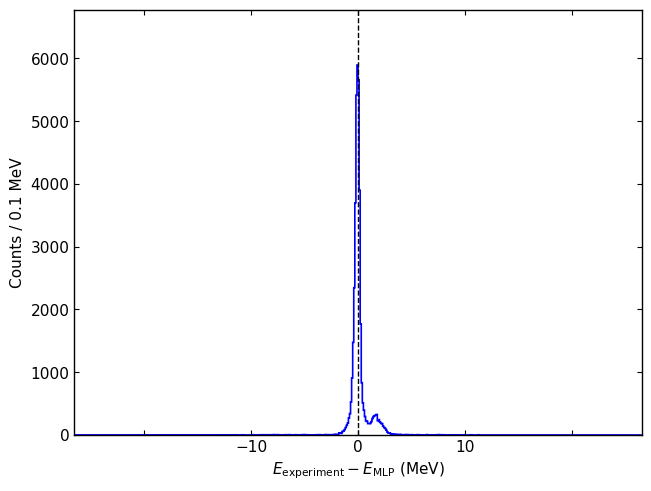

Energy difference: 39860 same-event pairs; histogram entries=39860
Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ADCToProtonEnergy/Exp/EnergyDiff.pdf


In [6]:
# 功能：输出左右臂合并的实验质子能量减 MLP 预测能量分布，保存 PDF、PNG 和分箱计数。
# 方法：复用推理结果的 ComparisonOK 同事件样本，NumPy 分箱后由 Matplotlib stairs 绘制无填充阶梯图，画布尺寸由 ENERGY_DIFFERENCE_FIGSIZE 调整。
# 注意事项：先运行第 1–4 节；能量单位 MeV；原 protonEnergy 不是真值；差值方向为实验减 MLP，
# 与已有 DeltaProtonEnergyNN 分支相反；不按能角图或激发能图范围裁剪；运行覆盖本单元格同名输出。
ENERGY_DIFFERENCE_BIN_WIDTH_MEV = 0.1  # 可在此调整 bin 宽。
ENERGY_DIFFERENCE_FIGSIZE = (6.4, 4.8)  # 画布宽、高，单位英寸。
energy_differences = []
for arm in ("Left", "Right"):
    arm_result = results[arm]
    common = arm_result["ComparisonOK"].astype(bool)
    energy_differences.append(arm_result["protonEnergy"][common]
                              - arm_result["ProtonEnergyNN"][common])
energy_differences = np.concatenate(energy_differences)
if energy_differences.size == 0:
    raise ValueError("没有同事件对照样本可用于质子能量差分布。")
# 对称范围覆盖全部有效差值，不使用显示范围再次筛选事件。
energy_difference_half_bins = max(1, int(np.ceil(
    np.max(np.abs(energy_differences)) / ENERGY_DIFFERENCE_BIN_WIDTH_MEV)))
energy_difference_limit = energy_difference_half_bins * ENERGY_DIFFERENCE_BIN_WIDTH_MEV
energy_difference_edges = np.linspace(-energy_difference_limit, energy_difference_limit,
                                      2 * energy_difference_half_bins + 1)
energy_difference_counts, _ = np.histogram(energy_differences, bins=energy_difference_edges)

energy_difference_fig, energy_difference_ax = plt.subplots(figsize=ENERGY_DIFFERENCE_FIGSIZE, layout="constrained")
energy_difference_ax.stairs(energy_difference_counts, energy_difference_edges,
                            fill=False, baseline=0.0, color="blue", linewidth=1.2, alpha=1.0)
energy_difference_ax.set(
    xlim=(-energy_difference_limit, energy_difference_limit),
    ylim=(0.0, max(1.0, 1.15 * energy_difference_counts.max())),
    xlabel=r"$E_{\mathrm{experiment}} - E_{\mathrm{MLP}}$ (MeV)",
    ylabel=f"Counts / {ENERGY_DIFFERENCE_BIN_WIDTH_MEV:g} MeV")
energy_difference_ax.set_box_aspect(1.0 / FRAME_ASPECT_RATIO)
energy_difference_ax.tick_params(direction="in", top=True, right=True)
energy_difference_ax.axvline(0.0, color="black", linestyle="--", linewidth=1.0)
energy_difference_fig.canvas.draw()
energy_difference_tick_labels = [tick.label1 for tick in energy_difference_ax.xaxis.get_major_ticks()
                                 if -energy_difference_limit <= tick.get_loc() <= energy_difference_limit
                                 and tick.label1.get_visible()]
if len(energy_difference_tick_labels) > 1:
    energy_difference_tick_labels[0].set_visible(False)
    energy_difference_tick_labels[-1].set_visible(False)
for suffix in ("pdf", "png"):
    energy_difference_fig.savefig(OUTPUT_DIR / f"EnergyDiff.{suffix}", dpi=200,
                                  bbox_inches="tight", pad_inches=0.06)
plt.show()
plt.close(energy_difference_fig)
np.savez(OUTPUT_DIR / "EnergyDiff.npz", edges_MeV=energy_difference_edges,
         counts=energy_difference_counts, difference_definition="protonEnergy - ProtonEnergyNN")
print(f"Energy difference: {energy_differences.size} same-event pairs; "
      f"histogram entries={energy_difference_counts.sum()}")
print("Saved:", OUTPUT_DIR / "EnergyDiff.pdf")


## 7. 按 Draw_8.C 生成运动学曲线

下个单元格调用 ROOT 辅助宏，质量来自 `NuclearMass::Get("10Be")` 与 `Get("1H")`。
曲线为 150 MeV/u 的 `Ex=0、3.368、6.179、10.15 MeV`，依次为参考宏的红、蓝、绿、品红，
实线、线宽1、透明度0.4；保留现有接口返回的两条运动学分支。
曲线及参数另存 CSV/JSON；不在 Python 中手写核质量或运动学公式。

In [7]:
# 功能：在 Exp 内生成并调用运动学辅助宏，导出曲线及质量来源。
# 方法：沿用已有 NuclearMass/TwoBodyKinematics 接口；不修改上级辅助宏。
# 注意事项：ROOT 与本地质量表必须可用；仅用户执行时调用 ROOT。
KINEMATICS_MACRO.write_text(r"""/*
 * 功能：向 Exp 导出实验能角对照图使用的两体运动学曲线和参数记录。
 * 方法：与 PictureForThesis/Draw_8.C 相同，计算 10Be(p,p)10Be、150 MeV/u、
 *       Ex=0、3.368、6.179、10.15 MeV；质量通过 NuclearMass 查询，调用现有
 *       TwoBodyKinematicsEnergyAngleProton，保留每条分支的点顺序及 ROOT 原色 RGB。
 * 注意事项：不读取实验数据、不加载模型、不训练；角度 deg、质子动能 MeV。
 *       质子质量数为 1，接口的质子 MeV/u 数值即总动能 MeV。
 *       需要本地 ROOT、TwoBodyKinematics、NuclearMass 和 nubtab20.asc。
 *       运行覆盖本宏所在目录（Exp）中的同名 CSV/JSON，不依赖启动目录。
 * 运行：root -l -b -q KinADC.C；ForADCExperiment.ipynb 也会调用本宏。
 */
#include "/Users/yemingxin/anaroot/output/Analysis/MyToolsFunction/TwoBodyKinematics/TwoBodyKinematics.h"
#include "/Users/yemingxin/anaroot/output/Analysis/MyToolsFunction/TwoBodyKinematics/TwoBodyKinematics.cc"
#include "/Users/yemingxin/anaroot/output/Analysis/MyToolsFunction/NuclearMass/NuclearMass.h"
#include "/Users/yemingxin/anaroot/output/Analysis/MyToolsFunction/NuclearMass/NuclearMass.cc"
#include "TColor.h"
#include "TGraph.h"
#include "TList.h"
#include "TMultiGraph.h"
#include "TROOT.h"
#include "TString.h"
#include "TSystem.h"
#include <cmath>
#include <fstream>
#include <iomanip>
#include <iostream>
#include <stdexcept>

namespace KinADCInternal {
const Double_t kBeamEnergyPerU = 150.0;
const Double_t kExcitationEnergy[4] = {0.0, 3.368, 6.179, 10.15};
const Color_t kLineColor[4] = {kRed + 1, kBlue + 1, kGreen + 2, kMagenta + 1};
const Float_t kLineAlpha = 0.4;
}

void KinADC()
{
  using namespace KinADCInternal;
  const TString outputDirectory = TString(gSystem->DirName(__FILE__));
  gSystem->mkdir(outputDirectory.Data(), kTRUE);
  const Double_t mass10BeAmu = NuclearMass::Get("10Be").MassAMU;
  const Double_t massProtonAmu = NuclearMass::Get("1H").MassAMU;

  std::ofstream curves((outputDirectory + "/KinCurves.csv").Data());
  if (!curves) throw std::runtime_error("Cannot create KinCurves.csv");
  curves << "StateIndex,Ex_MeV,CurveBranch,PointIndex,Theta_deg,ProtonEnergy_MeV,Red,Green,Blue\n";
  curves << std::setprecision(17);
  Long64_t savedPoints = 0;
  for (Int_t state = 0; state < 4; ++state) {
    TMultiGraph* multiGraph = TwoBodyKinematicsEnergyAngleProton(
        kBeamEnergyPerU, kExcitationEnergy[state],
        mass10BeAmu, massProtonAmu, massProtonAmu, mass10BeAmu,
        kLineColor[state], 1, kSolid, kLineAlpha);
    TColor* color = gROOT->GetColor(kLineColor[state]);
    if (!color) throw std::runtime_error("ROOT reference line color is unavailable");
    for (Int_t branch = 0; branch < multiGraph->GetListOfGraphs()->GetSize(); ++branch) {
      TGraph* graph = (TGraph*)multiGraph->GetListOfGraphs()->At(branch);
      for (Int_t point = 0; point < graph->GetN(); ++point) {
        Double_t theta = 0.0, energy = 0.0;
        graph->GetPoint(point, theta, energy);
        if (!std::isfinite(theta) || !std::isfinite(energy)) continue;
        curves << state << ',' << kExcitationEnergy[state] << ',' << branch << ',' << point << ','
               << theta << ',' << energy << ',' << color->GetRed() << ',' << color->GetGreen() << ',' << color->GetBlue() << '\n';
        ++savedPoints;
      }
    }
    delete multiGraph;
  }
  curves.close();
  if (!curves || savedPoints == 0) throw std::runtime_error("Kinematic curve export failed");

  std::ofstream metadata((outputDirectory + "/KinConfig.json").Data());
  if (!metadata) throw std::runtime_error("Cannot create KinConfig.json");
  metadata << std::setprecision(17)
           << "{\n  \"reaction\": \"10Be(p,p)10Be\",\n"
           << "  \"reference_macro\": \"/Users/yemingxin/RIKEN_Inelastic_Be/ppBe10/PictureForThesis/Draw_8.C\",\n"
           << "  \"beam_energy_per_u_MeV\": " << kBeamEnergyPerU << ",\n"
           << "  \"excitation_MeV\": [0.0, 3.368, 6.179, 10.15],\n"
           << "  \"mass_10Be_u\": " << mass10BeAmu << ",\n"
           << "  \"mass_proton_u\": " << massProtonAmu << ",\n"
           << "  \"mass_table\": \"" << NuclearMass::DefaultTablePath << "\",\n"
           << "  \"angle_unit\": \"deg\", \"proton_energy_unit\": \"MeV\",\n"
           << "  \"line_alpha\": " << kLineAlpha << ", \"line_width\": 1, \"line_style\": \"solid\",\n"
           << "  \"points\": " << savedPoints << "\n}\n";
  metadata.close();
  if (!metadata) throw std::runtime_error("Kinematic parameter export failed");
  std::cout << "Kinematics: 150 MeV/u, Ex=0/3.368/6.179/10.15 MeV; points=" << savedPoints
            << "; output=" << outputDirectory << std::endl;
}
""", encoding="utf-8")
if not KINEMATICS_MACRO.is_file():
    raise FileNotFoundError(f"缺少运动学辅助宏：{KINEMATICS_MACRO}")
if not Path(ROOT_EXECUTABLE).is_file():
    raise FileNotFoundError("未找到 ROOT 可执行文件，请修改配置中的 ROOT_EXECUTABLE。")
command = [str(ROOT_EXECUTABLE), "-l", "-b", "-q", str(KINEMATICS_MACRO)]
completed = subprocess.run(command, cwd=OUTPUT_DIR, text=True, capture_output=True)
print(completed.stdout)
if completed.stderr:
    print(completed.stderr)
completed.check_returncode()
curve_path = OUTPUT_DIR / "KinCurves.csv"
kinematics_configuration = json.loads((OUTPUT_DIR / "KinConfig.json").read_text())
curve_points = np.atleast_1d(np.genfromtxt(curve_path, delimiter=",", names=True))
if len(curve_points) == 0 or len(curve_points) != kinematics_configuration["points"]:
    raise ValueError("运动学曲线点数与导出参数不一致。")
if not np.isfinite(curve_points["Theta_deg"]).all() or not np.isfinite(curve_points["ProtonEnergy_MeV"]).all():
    raise ValueError("运动学曲线含非有限值。")
curves = []
for state in np.unique(curve_points["StateIndex"]):
    state_points = curve_points[curve_points["StateIndex"] == state]
    for branch in np.unique(state_points["CurveBranch"]):
        points = state_points[state_points["CurveBranch"] == branch]
        points = np.sort(points, order="PointIndex")
        curves.append({
            "excitation": float(points["Ex_MeV"][0]), "branch": int(branch),
            "theta": points["Theta_deg"], "energy": points["ProtonEnergy_MeV"],
            "color": tuple(float(points[name][0]) for name in ("Red", "Green", "Blue")),
        })
print("Kinematics:", kinematics_configuration["beam_energy_per_u_MeV"], "MeV/u; Ex=", kinematics_configuration["excitation_MeV"])


add include path : /Users/yemingxin/anaroot/src/install/include
reading libXMLParser.so
reading libananadeko.dylib
reading libanacore.dylib
reading libanabrips.dylib
reading libanadali.dylib
reading libanasamurai.dylib
reading libanacatana.dylib
reading libanaespri.dylib
reading libanawinds.dylib
reading libanasilicons.dylib
reading libanatogaxsi.dylib
reading libanaloop.dylib
reading libanaloopexample.dylib
reading libanaloopencexample.dylib
Processing /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ADCToProtonEnergy/Exp/KinADC.C...
Kinematics: 150 MeV/u, Ex=0/3.368/6.179/10.15 MeV; points=71576; output=/Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ADCToProtonEnergy/Exp

Kinematics: 150 MeV/u; Ex= [0.0, 3.368, 6.179, 10.15]


## 8. 同事件的质子动能—角度二维图与运动学叠加

三行依次为 Left、Right、左右臂合并（Left + Right）；左列为原 `protonEnergy`，右列为 `ProtonEnergyNN`。
合并图逐 bin 相加两臂的原始计数，不取平均；各臂仍使用相同的 `ComparisonOK` 样本。
横轴显示角度 50–80°、bin 宽0.1°；事件角度筛选仍为 55–70°。动能 0–180 MeV、bin 宽0.1 MeV。
六图保持原始计数，使用共同彩虹（rainbow）对数色标，绘图区均为4:3；曲线只作理论位置对照。
显示范围外的事件计数会报告，不用显示范围重新筛选或修改预测。

Left Original {'visible_events': 19957, 'outside_display': 0}
Left NN {'visible_events': 19957, 'outside_display': 0}
Right Original {'visible_events': 19903, 'outside_display': 0}
Right NN {'visible_events': 19903, 'outside_display': 0}
Combined Original {'visible_events': 39860, 'outside_display': 0}
Combined NN {'visible_events': 39860, 'outside_display': 0}


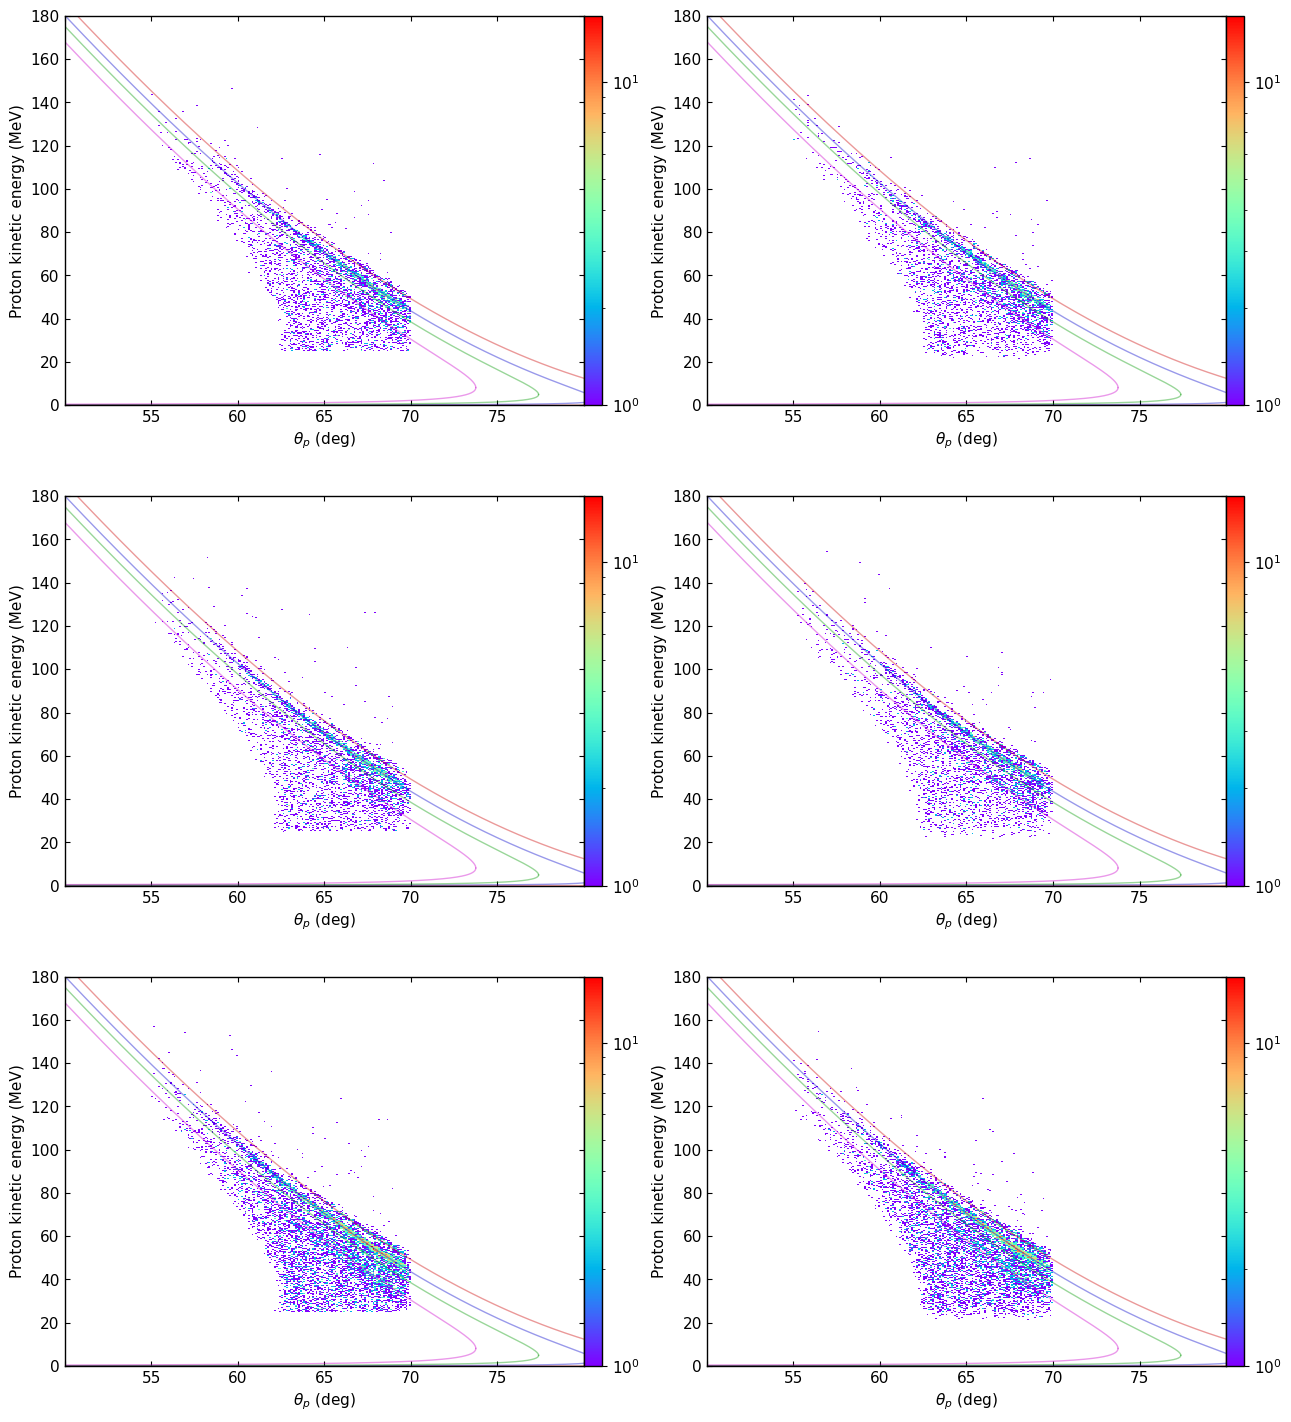

Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ADCToProtonEnergy/Exp/EnergyAngle.pdf


In [8]:
angle_edges = np.linspace(PLOT_THETA_MIN_DEG, PLOT_THETA_MAX_DEG,
                          int(round((PLOT_THETA_MAX_DEG - PLOT_THETA_MIN_DEG) / THETA_BIN_WIDTH_DEG)) + 1)
energy_edges = np.linspace(ENERGY_MIN_MEV, ENERGY_MAX_MEV,
                           int(round((ENERGY_MAX_MEV - ENERGY_MIN_MEV) / ENERGY_BIN_WIDTH_MEV)) + 1)
histograms = {}
plot_counts = {}
for arm in ("Left", "Right"):
    result = results[arm]
    common = result["ComparisonOK"].astype(bool)
    plot_counts[arm] = {"common_events": int(common.sum())}
    for label, branch in [("Original", "protonEnergy"), ("NN", "ProtonEnergyNN")]:
        histogram, _, _ = np.histogram2d(result["protonTheta"][common], result[branch][common],
                                         bins=(angle_edges, energy_edges))
        histograms[f"{arm}_{label}"] = histogram
        plot_counts[arm][label] = {
            "visible_events": int(histogram.sum()),
            "outside_display": int(common.sum() - histogram.sum()),
        }
        print(arm, label, plot_counts[arm][label])

# 两臂事件互斥且共用分箱；逐 bin 相加得到合并样本，保留原始计数。
plot_counts["Combined"] = {
    "common_events": sum(plot_counts[arm]["common_events"] for arm in ("Left", "Right"))
}
for label in ("Original", "NN"):
    histograms[f"Combined_{label}"] = histograms[f"Left_{label}"] + histograms[f"Right_{label}"]
    plot_counts["Combined"][label] = {
        key: sum(plot_counts[arm][label][key] for arm in ("Left", "Right"))
        for key in ("visible_events", "outside_display")
    }
    print("Combined", label, plot_counts["Combined"][label])

maximum = max(2.0, max(histogram.max() for histogram in histograms.values()))
normalization = LogNorm(vmin=1.0, vmax=maximum)
color_map = plt.get_cmap(COLOR_MAP).copy()
color_map.set_bad("white")
fig, axes = plt.subplots(3, 2, figsize=(12.8, 14.4), layout="constrained")
for row, arm in enumerate(("Left", "Right", "Combined")):
    for column, label in enumerate(("Original", "NN")):
        ax = axes[row, column]
        histogram = histograms[f"{arm}_{label}"]
        mesh = ax.pcolormesh(angle_edges, energy_edges, np.ma.masked_less_equal(histogram.T, 0),
                             cmap=color_map, norm=normalization, shading="flat", rasterized=True)
        for curve in curves:
            ax.plot(curve["theta"], curve["energy"], color=curve["color"],
                    alpha=kinematics_configuration["line_alpha"], linewidth=1, linestyle="-")
        ax.set(xlim=(PLOT_THETA_MIN_DEG, PLOT_THETA_MAX_DEG), ylim=(ENERGY_MIN_MEV, ENERGY_MAX_MEV),
               xlabel=r"$\theta_p$ (deg)", ylabel="Proton kinetic energy (MeV)")
        method = "original reconstruction" if label == "Original" else "neural network"
        arm_title = "Left + Right" if arm == "Combined" else arm
        ax.set_box_aspect(1.0 / FRAME_ASPECT_RATIO)
        ax.grid(False)
        ax.tick_params(direction="in", top=True, right=True)
        panel_label = chr(ord("a") + 3 * column + row)
# 每个子图使用与实际绘图区等高的无标题颜色条。
for ax in axes.flat:
    cax = ax.inset_axes([1.0, 0.0, 0.035, 1.0], transform=ax.transAxes)
    fig.colorbar(mesh, cax=cax)
fig.canvas.draw()
for ax in axes.flat:
    lower, upper = ax.get_xlim()
    visible_labels = [tick.label1 for tick in ax.xaxis.get_major_ticks()
                      if lower <= tick.get_loc() <= upper and tick.label1.get_visible()]
    if len(visible_labels) > 1:
        visible_labels[0].set_visible(False)
        visible_labels[-1].set_visible(False)
pdf_path = OUTPUT_DIR / "EnergyAngle.pdf"
fig.savefig(pdf_path, dpi=200, bbox_inches="tight", pad_inches=0.06)
fig.savefig(OUTPUT_DIR / "EnergyAngle.png", dpi=180, bbox_inches="tight", pad_inches=0.06)
plt.show()
plt.close(fig)
np.savez(OUTPUT_DIR / "AngleHist.npz", angle_edges=angle_edges, energy_edges=energy_edges, **histograms)
plot_summary = {
    "counts": plot_counts, "theta_range_deg": [PLOT_THETA_MIN_DEG, PLOT_THETA_MAX_DEG],
    "energy_range_MeV": [ENERGY_MIN_MEV, ENERGY_MAX_MEV],
    "theta_bin_deg": THETA_BIN_WIDTH_DEG, "energy_bin_MeV": ENERGY_BIN_WIDTH_MEV,
    "shared_color_scale": {"vmin": 1.0, "vmax": float(maximum), "scale": "log", "normalization": "raw counts"},
    "kinematics": kinematics_configuration,
}
(OUTPUT_DIR / "PlotSummary.json").write_text(json.dumps(plot_summary, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print("Saved:", pdf_path)


Original {'visible_events': 39801, 'underflow': 59, 'overflow': 0}
NN {'visible_events': 39800, 'underflow': 60, 'overflow': 0}
Input events=39860, common valid events=39860, invalid original=0, invalid MLP=0


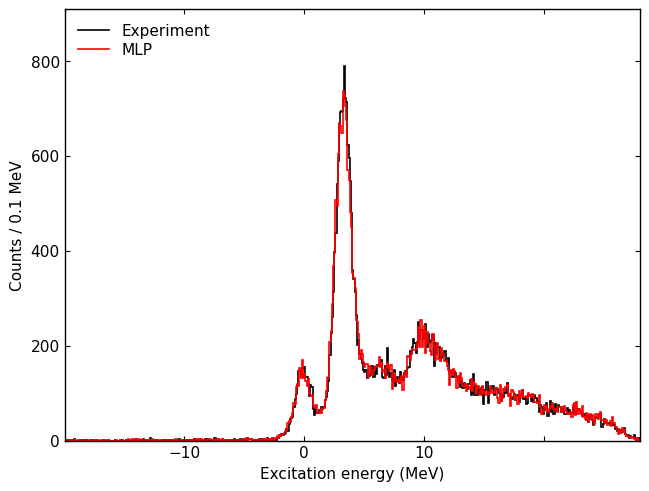

Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ADCToProtonEnergy/Exp/ExCompare.pdf


<IPython.core.display.Math object>

In [9]:
# 功能：同事件重建传统实验与 ADC MLP 的激发能并保存双谱缓存。
# 方法：150 MeV/u，经 NuclearMass/TwoBodyKinematics 缺失质量接口；逐行核对 SourceEntry/espriSide。
# 注意事项：ROOT 辅助宏和中间文件仅写 Exp/exwork；无 GPR 模型加载；传统能量不是真值。
EX_MIN_MEV, EX_MAX_MEV, EX_BIN_WIDTH_MEV = (-20.0, 30.0, 0.1)
EX_DISPLAY_RANGE_MEV = (-20.0, 28.0)
ex_edges = np.linspace(EX_MIN_MEV, EX_MAX_MEV, int(round((EX_MAX_MEV - EX_MIN_MEV) / EX_BIN_WIDTH_MEV)) + 1)
ex_inputs = []
ex_source_entries, ex_sides = ([], [])
for arm in ('Left', 'Right'):
    arm_result = results[arm]
    common = arm_result['ComparisonOK'].astype(bool)
    ex_inputs.append(np.column_stack((arm_result['protonTheta'][common], arm_result['protonEnergy'][common], arm_result['ProtonEnergyNN'][common])))
    ex_source_entries.append(arm_result['SourceEntry'][common])
    ex_sides.append(arm_result['espriSide'][common])
ex_inputs = np.concatenate(ex_inputs, axis=0)
ex_source_entries = np.concatenate(ex_source_entries)
ex_sides = np.concatenate(ex_sides)
if len(ex_inputs) == 0:
    raise ValueError('没有实验与必需 MLP 的同事件对照样本可用于激发能重建。')
ex_beam_total_mev = 10.0 * float(kinematics_configuration['beam_energy_per_u_MeV'])
ex_macro_source = r"""// 功能：逐事件计算原重建与 ADC MLP 两种质子动能对应的 10Be 激发能。
// 方法：NuclearMass 的 MassAMU（u）质量和 TwoBodyKinematicsMissingMass；原样返回 SourceEntry、espriSide。
// 注意事项：输入为实验同事件角度及两种能量；束流总动能 MeV，角度 deg；失败值 -999 配合有效标志。
#include "/Users/yemingxin/anaroot/output/Analysis/MyToolsFunction/TwoBodyKinematics/TwoBodyKinematics.h"
#include "/Users/yemingxin/anaroot/output/Analysis/MyToolsFunction/TwoBodyKinematics/TwoBodyKinematics.cc"
#include "/Users/yemingxin/anaroot/output/Analysis/MyToolsFunction/NuclearMass/NuclearMass.h"
#include "/Users/yemingxin/anaroot/output/Analysis/MyToolsFunction/NuclearMass/NuclearMass.cc"
#include "TMath.h"
#include <cmath>
#include <fstream>
#include <iomanip>
#include <stdexcept>
void CalcEx() {
    const Double_t kInvalidValue = -999.0;
    const Double_t massBe = NuclearMass::Get("10Be").MassMeV;
    const Double_t massBeAmu = NuclearMass::Get("10Be").MassAMU;
    const Double_t massPAmu = NuclearMass::Get("1H").MassAMU;
    const Double_t beamEnergy = __BEAM_TOTAL_MEV__;
    std::ifstream input("ExInput.txt");
    std::ofstream output("ExValues.csv");
    if (!input || !output) throw std::runtime_error("Cannot open excitation input/output");
    output << "SourceEntry,espriSide,ExOriginal_MeV,ExNN_MeV,OriginalOK,NNOK\n"
           << std::setprecision(17);
    Long64_t sourceEntry = 0;
    Int_t side = 0;
    Double_t theta = 0.0, originalEnergy = 0.0, nnEnergy = 0.0;
    while (input >> sourceEntry >> side >> theta >> originalEnergy >> nnEnergy) {
        const Double_t energies[2] = {originalEnergy, nnEnergy};
        Double_t excitation[2] = {kInvalidValue, kInvalidValue};
        Int_t valid[2] = {0, 0};
        for (Int_t method = 0; method < 2; ++method) {
            if (!std::isfinite(theta) || theta < 0.0 || theta > 180.0
                || !std::isfinite(energies[method]) || energies[method] <= 0.0
                || massBe + beamEnergy - energies[method] <= 0.0) continue;
            const Double_t value = TwoBodyKinematicsMissingMass(
                massBeAmu, massPAmu, massPAmu, massBeAmu, beamEnergy, energies[method],
                std::cos(theta * TMath::DegToRad()));
            if (std::isfinite(value)) {
                excitation[method] = value;
                valid[method] = 1;
            }
        }
        output << sourceEntry << ',' << side;
        for (Int_t method = 0; method < 2; ++method) output << ',' << excitation[method];
        for (Int_t method = 0; method < 2; ++method) output << ',' << valid[method];
        output << '\n';
    }
    output.close();
    if (!input.eof() || !output) throw std::runtime_error("Excitation data transfer failed");
}
""".replace("__BEAM_TOTAL_MEV__", format(ex_beam_total_mev, ".17g"))
ex_temp_path = OUTPUT_DIR / 'exwork'
ex_temp_path.mkdir(exist_ok=True)
ex_transfer = np.column_stack((ex_source_entries, ex_sides, ex_inputs))
np.savetxt(ex_temp_path / 'ExInput.txt', ex_transfer, fmt=['%d', '%d'] + ['%.17g'] * 3)
ex_macro = ex_temp_path / 'CalcEx.C'
ex_macro.write_text(ex_macro_source, encoding='utf-8')
ex_run = subprocess.run([str(ROOT_EXECUTABLE), '-l', '-b', '-q', str(ex_macro)], cwd=ex_temp_path, text=True, capture_output=True)
if ex_run.returncode:
    print(ex_run.stdout)
    print(ex_run.stderr)
ex_run.check_returncode()
ex_values = np.atleast_1d(np.genfromtxt(ex_temp_path / 'ExValues.csv', delimiter=',', names=True, dtype=None, encoding='utf-8'))
if len(ex_values) != len(ex_inputs):
    raise ValueError('激发能输出行数与输入不一致，不能保证事件对齐。')
if not np.array_equal(ex_values['SourceEntry'], ex_source_entries) or not np.array_equal(ex_values['espriSide'], ex_sides):
    raise ValueError('激发能输出的 SourceEntry/espriSide 与实验输入不一致。')
ex_original_ok = ex_values['OriginalOK'].astype(bool)
ex_nn_ok = ex_values['NNOK'].astype(bool)
ex_pair_ok = ex_original_ok & ex_nn_ok
ex_comparison_ok = ex_pair_ok
ex_spectrum_methods = [('Original', 'ExOriginal_MeV', '#000000', 'Experiment'), ('NN', 'ExNN_MeV', '#FF0000', 'MLP')]
ex_histograms, ex_statistics = ({}, {})
for method, branch, _, _ in ex_spectrum_methods:
    values = ex_values[branch][ex_comparison_ok]
    ex_histograms[method], _ = np.histogram(values, bins=ex_edges)
    ex_statistics[method] = {'visible_events': int(ex_histograms[method].sum()), 'underflow': int((values < EX_MIN_MEV).sum()), 'overflow': int((values > EX_MAX_MEV).sum())}
    print(method, ex_statistics[method])
print(f'Input events={len(ex_inputs)}, common valid events={ex_comparison_ok.sum()}, invalid original={(~ex_original_ok).sum()}, invalid MLP={(~ex_nn_ok).sum()}')
if not ex_comparison_ok.any():
    raise ValueError('没有当前启用方法均有效的同事件，不能绘制激发能谱对照。')
ex_fig, ex_ax = plt.subplots(figsize=(6.4, 4.8), layout='constrained')
for method, _, color, label in ex_spectrum_methods:
    ex_ax.stairs(ex_histograms[method], ex_edges, fill=False, baseline=0.0, color=color, linewidth=1.2, alpha=1.0, label=label)
ex_ax.set(xlim=EX_DISPLAY_RANGE_MEV, ylim=(0.0, max(1.0, 1.15 * max((h.max() for h in ex_histograms.values())))), xlabel='Excitation energy (MeV)', ylabel=f'Counts / {ex_edges[1] - ex_edges[0]:g} MeV')
ex_ax.set_box_aspect(1.0 / FRAME_ASPECT_RATIO)
ex_ax.tick_params(direction='in', top=True, right=True)
ex_ax.legend(loc='upper left', frameon=False, labelspacing=0.25)
ex_fig.canvas.draw()
ex_tick_labels = [tick.label1 for tick in ex_ax.xaxis.get_major_ticks() if EX_DISPLAY_RANGE_MEV[0] <= tick.get_loc() <= EX_DISPLAY_RANGE_MEV[1] and tick.label1.get_visible()]
if len(ex_tick_labels) > 1:
    ex_tick_labels[0].set_visible(False)
    ex_tick_labels[-1].set_visible(False)
for suffix in ('pdf', 'png'):
    ex_fig.savefig(OUTPUT_DIR / f'ExCompare.{suffix}', dpi=200, bbox_inches='tight', pad_inches=0.06)
plt.show()
plt.close(ex_fig)
ex_cache = {'edges_MeV': ex_edges, 'Original': ex_histograms['Original'], 'NN': ex_histograms['NN'], 'SourceEntry': ex_source_entries, 'espriSide': ex_sides, 'ExOriginal_MeV': ex_values['ExOriginal_MeV'], 'ExNN_MeV': ex_values['ExNN_MeV'], 'ProtonTheta_deg': ex_inputs[:, 0], 'ProtonEnergyOriginal_MeV': ex_inputs[:, 1], 'ProtonEnergyMLP_MeV': ex_inputs[:, 2], 'OriginalOK': ex_original_ok, 'NNOK': ex_nn_ok, 'PairOK': ex_pair_ok, 'ComparisonOK': ex_comparison_ok}
np.savez(OUTPUT_DIR / 'ExCompare.npz', **ex_cache)
ex_summary = {'reaction': '10Be(p,p)10Be', 'beam_energy_total_MeV': ex_beam_total_mev, 'theta_selection_deg': [THETA_MIN_DEG, THETA_MAX_DEG], 'range_MeV': [EX_MIN_MEV, EX_MAX_MEV], 'display_range_MeV': list(EX_DISPLAY_RANGE_MEV), 'bin_width_MeV': EX_BIN_WIDTH_MEV, 'input_pairs': int(len(ex_inputs)), 'valid_pairs': int(ex_pair_ok.sum()), 'common_events': int(ex_comparison_ok.sum()), 'invalid_original': int((~ex_original_ok).sum()), 'invalid_NN': int((~ex_nn_ok).sum()), 'normalization': 'raw counts; same experimental events valid for all enabled methods', 'counts': ex_statistics}
(OUTPUT_DIR / 'ExSummary.json').write_text(json.dumps(ex_summary, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
print('Saved:', OUTPUT_DIR / 'ExCompare.pdf')

display(Math(r"E_x=\sqrt{(P_{\mathrm{beam}}+P_{\mathrm{target}}-P_p)^2}-M_{^{10}\mathrm{Be}}"))


## 输出
所有结果保存在本文件夹 Exp 内，包括两臂 ROOT/CSV、模型来源与 cutflow JSON、能量差、能角图、激发能双谱及局部高斯拟合。原 protonEnergy 仅为传统重建对照。


## 9. 两种重建的局部单高斯峰拟合
沿用原窗口 gs=(-1,1)、first=(2.3,4.3) MeV，不按 ADC 结果调整拟合窗口。


Original gs   : mu=-0.0338, sigma=0.6788 +/- 0.0255 MeV, deviance/ndf=6.15
Original first: mu=3.3129, sigma=0.6698 +/- 0.0111 MeV, deviance/ndf=0.20
MLP      gs   : mu=-0.0481, sigma=0.7301 +/- 0.0314 MeV, deviance/ndf=3.01
MLP      first: mu=3.2778, sigma=0.7131 +/- 0.0133 MeV, deviance/ndf=1.29


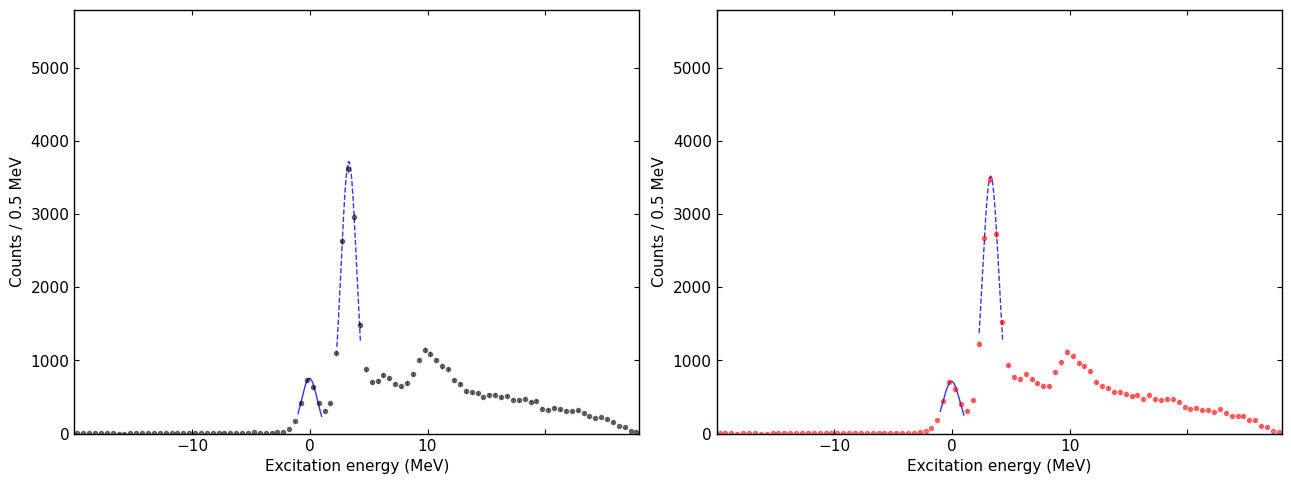

Saved: /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/ADCToProtonEnergy/Exp/PeakFits.pdf


<IPython.core.display.Math object>

In [10]:
# 功能：对同事件传统实验/ADC MLP 激发能谱分别做基态和第一激发态局部高斯拟合。
# 方法：沿用原 iminuit 窗口归一化非分箱扩展似然及 HESSE 误差，不共享峰参数。
# 注意事项：固定窗口与原 Notebook 相同；无本底；sigma 不是本征分辨率；结果仅供用户执行后判断。
import csv
from iminuit import Minuit
from scipy.special import ndtr, xlogy
PEAK_FIT_WINDOWS_MEV = {'gs': (-1.0, 1.0), 'first': (2.3, 4.3)}
PEAK_FIT_DISPLAY_MEV = (-20.0, 28.0)
PEAK_FIT_BIN_WIDTH_MEV = 0.5
PEAK_FIT_SIGMA_LIMITS_MEV = (0.1, 2.0)
peak_fit_input = OUTPUT_DIR / 'ExCompare.npz'
with np.load(peak_fit_input, allow_pickle=False) as peak_saved:
    required = {'PairOK', 'ExOriginal_MeV', 'ExNN_MeV'}
    if not required.issubset(peak_saved.files):
        raise ValueError('激发能缓存必须包含实验、MLP 及 PairOK，请先运行前一个代码单元格。')
    peak_mask_name = 'PairOK'
    peak_pair_ok = peak_saved[peak_mask_name].astype(bool)
    peak_arrays = {'Original': np.asarray(peak_saved['ExOriginal_MeV'][peak_pair_ok], dtype=np.float64), 'MLP': np.asarray(peak_saved['ExNN_MeV'][peak_pair_ok], dtype=np.float64)}
peak_methods = [('Original', 'Original experimental reconstruction', '#000000'), ('MLP', 'MLP reconstruction of experimental events', '#FF0000')]
PEAK_FIT_FIGSIZE = (6.4 * len(peak_methods), 4.8)
peak_fit_labels = {'gs': 'Ground state', 'first': 'First excited state'}

def fit_local_peak(values, bounds):
    """每个峰独立做窗口归一化的单高斯扩展似然拟合。"""
    low, high = bounds
    data = values[(values >= low) & (values <= high)]
    count = len(data)
    if count < 4:
        raise ValueError(f'拟合窗口 {bounds} 内事件不足：{count}')

    def nll(n, mu, sigma):
        norm = ndtr((high - mu) / sigma) - ndtr((low - mu) / sigma)
        return n - count * np.log(n) + count * (np.log(sigma) + 0.5 * np.log(2.0 * np.pi) + np.log(norm)) + 0.5 * np.sum(((data - mu) / sigma) ** 2)
    fit = Minuit(nll, n=count, mu=(low + high) / 2.0, sigma=0.65)
    fit.errordef = Minuit.LIKELIHOOD
    fit.limits['n'] = (0.0, 2.0 * count)
    fit.limits['mu'] = (low, high)
    fit.limits['sigma'] = PEAK_FIT_SIGMA_LIMITS_MEV
    fit.migrad()
    fit.hesse()
    if not fit.valid or not fit.accurate or fit.fmin.has_parameters_at_limit:
        raise RuntimeError(f'窗口 {bounds} 的拟合或误差需要检查：{fit.fmin}')
    mu, sigma = (fit.values['mu'], fit.values['sigma'])
    edges = np.linspace(low, high, int(round((high - low) / PEAK_FIT_BIN_WIDTH_MEV)) + 1)
    norm = ndtr((high - mu) / sigma) - ndtr((low - mu) / sigma)
    expected = fit.values['n'] * np.diff(ndtr((edges - mu) / sigma)) / norm
    observed = np.histogram(data, bins=edges)[0]
    deviance = 2.0 * np.sum(expected - observed + xlogy(observed, observed / expected))
    ndf = len(observed) - fit.nfit
    return {'range_MeV': list(bounds), 'fit_events': count, 'mu_MeV': float(mu), 'mu_err_MeV': float(fit.errors['mu']), 'sigma_MeV': float(sigma), 'sigma_err_MeV': float(fit.errors['sigma']), 'yield': float(fit.values['n']), 'yield_err': float(fit.errors['n']), 'covariance_order': ['mu', 'sigma'], 'covariance': np.asarray(fit.covariance)[1:, 1:].tolist(), 'converged': bool(fit.valid), 'accurate_covariance': bool(fit.accurate), 'parameters_at_limit': bool(fit.fmin.has_parameters_at_limit), 'edm': float(fit.fmin.edm), 'poisson_deviance': float(deviance), 'ndf': ndf, 'deviance_per_ndf': float(deviance / ndf)}
peak_fit_results = {method: {state: fit_local_peak(values, bounds) for state, bounds in PEAK_FIT_WINDOWS_MEV.items()} for method, values in peak_arrays.items()}
peak_plot_edges = np.linspace(*PEAK_FIT_DISPLAY_MEV, int(round((PEAK_FIT_DISPLAY_MEV[1] - PEAK_FIT_DISPLAY_MEV[0]) / PEAK_FIT_BIN_WIDTH_MEV)) + 1)
peak_plot_bin_width = float(peak_plot_edges[1] - peak_plot_edges[0])
peak_plot_centers = (peak_plot_edges[:-1] + peak_plot_edges[1:]) / 2.0
peak_plot_counts = {method: np.histogram(values, bins=peak_plot_edges)[0] for method, values in peak_arrays.items()}
peak_plot_ymax = max(1.0, 1.6 * max((counts.max() for counts in peak_plot_counts.values())))
peak_fit_fig, peak_fit_axes = plt.subplots(1, len(peak_methods), figsize=PEAK_FIT_FIGSIZE, layout='constrained')
for column, (method, title, color) in enumerate(peak_methods):
    ax = peak_fit_axes[column]
    counts = peak_plot_counts[method]
    ax.errorbar(peak_plot_centers, counts, yerr=np.sqrt(counts), fmt='o', color=color, markersize=3.0, elinewidth=0.7, capsize=0, linestyle='none', alpha=0.5)
    for state, linestyle in (('gs', '-'), ('first', '--')):
        result = peak_fit_results[method][state]
        low, high = result['range_MeV']
        x = np.linspace(low, high, 400)
        mu, sigma = (result['mu_MeV'], result['sigma_MeV'])
        norm = ndtr((high - mu) / sigma) - ndtr((low - mu) / sigma)
        curve = result['yield'] * np.exp(-0.5 * ((x - mu) / sigma) ** 2)
        curve *= peak_plot_bin_width / (np.sqrt(2.0 * np.pi) * sigma * norm)
        ax.plot(x, curve, color='blue', linewidth=1.0, alpha=0.8, linestyle=linestyle)
        print(f"{method:8s} {state:5s}: mu={mu:.4f}, sigma={sigma:.4f} +/- {result['sigma_err_MeV']:.4f} MeV, deviance/ndf={result['deviance_per_ndf']:.2f}")
    ax.set(xlim=PEAK_FIT_DISPLAY_MEV, ylim=(0.0, peak_plot_ymax), xlabel='Excitation energy (MeV)', ylabel=f'Counts / {peak_plot_bin_width:g} MeV')
    ax.set_box_aspect(1.0 / FRAME_ASPECT_RATIO)
    ax.tick_params(direction='in', top=True, right=True)
peak_fit_fig.canvas.draw()
for ax in peak_fit_axes:
    low, high = ax.get_xlim()
    labels = [tick.label1 for tick in ax.xaxis.get_major_ticks() if low <= tick.get_loc() <= high and tick.label1.get_visible()]
    if len(labels) > 1:
        labels[0].set_visible(False)
        labels[-1].set_visible(False)
for suffix in ('pdf', 'png'):
    peak_fit_fig.savefig(OUTPUT_DIR / f'PeakFits.{suffix}', dpi=200, bbox_inches='tight', pad_inches=0.06)
plt.show()
plt.close(peak_fit_fig)
peak_fit_summary = {'input': str(peak_fit_input.resolve()), 'input_sha256': hashlib.sha256(peak_fit_input.read_bytes()).hexdigest(), 'common_events': int(peak_pair_ok.sum()), 'fit_windows_MeV': PEAK_FIT_WINDOWS_MEV, 'fit_method': 'iminuit MIGRAD; independent window-normalized unbinned extended Gaussian likelihood; no background', 'error_method': 'iminuit HESSE; statistical errors only', 'display_range_MeV': list(PEAK_FIT_DISPLAY_MEV), 'display_bin_width_MeV': peak_plot_bin_width, 'comparison': 'Traditional reconstruction and ADC MLP on the same experimental events', 'methods': list(peak_arrays), 'event_mask': peak_mask_name, 'fits': peak_fit_results}
(OUTPUT_DIR / 'PeakFits.json').write_text(json.dumps(peak_fit_summary, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
with (OUTPUT_DIR / 'PeakFits.csv').open('w', newline='', encoding='utf-8') as stream:
    writer = csv.writer(stream)
    writer.writerow(['method', 'state', 'fit_min_MeV', 'fit_max_MeV', 'fit_events', 'mu_MeV', 'mu_err_MeV', 'sigma_MeV', 'sigma_err_MeV', 'deviance_per_ndf'])
    for method, states in peak_fit_results.items():
        for state, result in states.items():
            writer.writerow([method, state, *result['range_MeV'], result['fit_events'], result['mu_MeV'], result['mu_err_MeV'], result['sigma_MeV'], result['sigma_err_MeV'], result['deviance_per_ndf']])
print('Saved:', OUTPUT_DIR / 'PeakFits.pdf')

display(Math(r"g(E_x)=\frac{N}{\sqrt{2\pi}\sigma Z}\exp\!\left[-\frac{(E_x-\mu)^2}{2\sigma^2}\right],\quad Z=\Phi((h-\mu)/\sigma)-\Phi((l-\mu)/\sigma)"))
